# วิเคราะห์คุณภาพไวน์: กราฟสำรวจ และโมเดลจัดกลุ่มคุณภาพ (Train / Test)

ข้อมูล: ไวน์โปรตุเกสแดงและขาว 6,497 ขวด สมบัติทางเคมี 11 ตัว คะแนน `quality` (3–9) และ `type` (red/white)

โครงสร้าง: 0. โหลดข้อมูล → 1. กราฟสำรวจ 3 กราฟ → 2. โมเดล Random Forest จัดกลุ่มคุณภาพ (ฝึก/ทดสอบ) → 3. ตรวจความเสถียรและตัวแปรสำคัญ

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# ---------------------------------------------------------------------------
# 0. ตั้งค่า path และโหลดข้อมูล (วางไฟล์ CSV ไว้โฟลเดอร์เดียวกับโน้ตบุ๊ก)
# ---------------------------------------------------------------------------
ROOT = Path(".")
DATA = ROOT / "ไฟล์งาน WINE.csv"
TAB = ROOT / "results" / "tables"
FIG = ROOT / "results" / "figures"
TAB.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA)
print(f"โหลดข้อมูล {len(df)} แถว {df.shape[1]} คอลัมน์ | ค่าว่าง {int(df.isna().sum().sum())} ค่า")

# แถวซ้ำ: ตัดออกก่อนแบ่งชุดฝึก/ทดสอบ เพื่อไม่ให้แถวเดียวกันอยู่ทั้งสองชุด
n_dup = int(df.duplicated().sum())
print(f"แถวที่ซ้ำกันทุกคอลัมน์ {n_dup} แถว -> ตัดออกเฉพาะตอนทำโมเดล")
df_unique = df.drop_duplicates().reset_index(drop=True)

FEATURES = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar",
            "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
            "pH", "sulphates", "alcohol"]

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3})
BLUE, ORANGE = "#2f6db5", "#e07b39"

def save(name):
    """บันทึกกราฟลง results/figures แล้วแสดงผล"""
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150)
    plt.show()
    print("บันทึกกราฟ:", name)


Matplotlib is building the font cache; this may take a moment.


โหลดข้อมูล 6497 แถว 13 คอลัมน์ | ค่าว่าง 0 ค่า
แถวที่ซ้ำกันทุกคอลัมน์ 1177 แถว -> ตัดออกเฉพาะตอนทำโมเดล


In [2]:
%pip install matplotlib pandas numpy scikit-learn scipy

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.5 MB 6.7 MB/s eta 0:00:02
   ----------- ---------------------------- 2.6/9.5 MB 6.7 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.5 MB 6.2 MB/s eta 0:00:01
   ---------------------- ----------------- 5.2/9.5 MB 6.0 MB/s eta 0:00:01
   -------------------------- ------------- 6.3/9.5 MB 6.1 MB/s eta 0:00:01
   --------------------------------- ------ 7.9/9.5 MB 6.2 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.5 MB 6.3 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 5.8 MB/s  0:00:01
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.8 MB 6.4 MB/s eta 0:00:02
   ---------- ----------------------------- 2.6/9.8 MB 6.5 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.8 MB 6.4 MB/s eta 0:00:01
   --------------------- ----

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


## 1. กราฟสำรวจข้อมูล

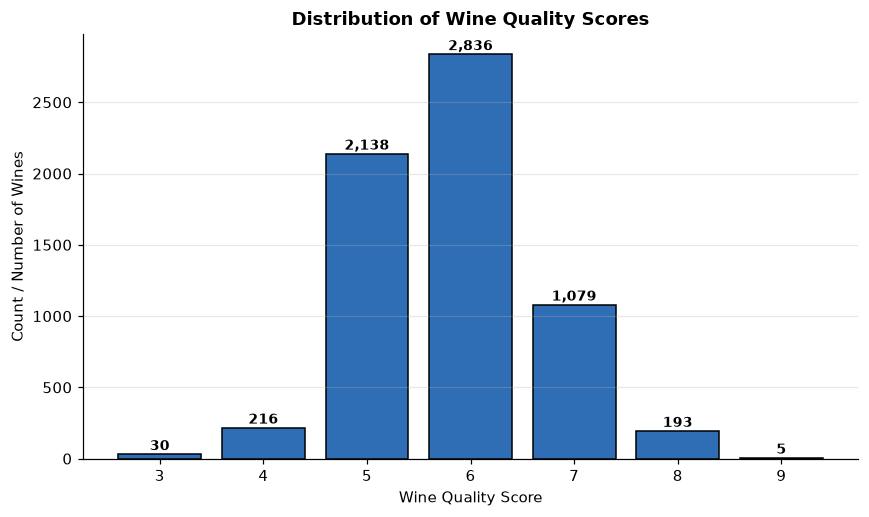

บันทึกกราฟ: fig01_quality_bar.png


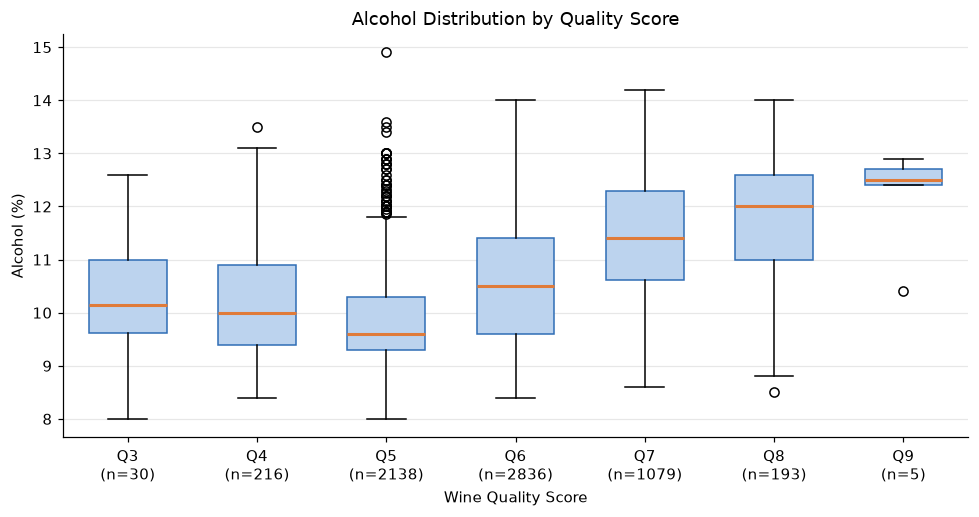

บันทึกกราฟ: fig02_alcohol_boxplot.png


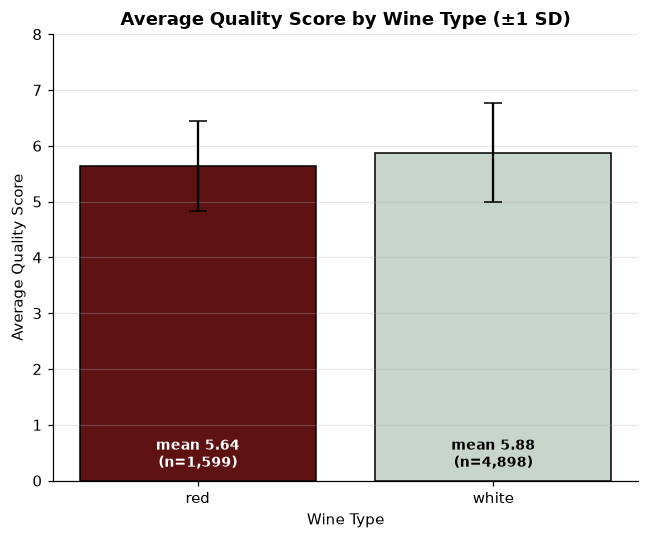

บันทึกกราฟ: fig03_quality_by_type.png


In [4]:
# กราฟที่ 1: จำนวนไวน์ตามคะแนนคุณภาพ (bar chart ใส่จำนวนทุกแท่ง)
cnt = df["quality"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.bar(cnt.index.astype(str), cnt.values, color=BLUE, edgecolor="black")
for b, v in zip(bars, cnt.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 30, f"{v:,}", ha="center",
            fontsize=9, fontweight="bold")
ax.set_xlabel("Wine Quality Score"); ax.set_ylabel("Count / Number of Wines")
ax.set_title("Distribution of Wine Quality Scores", fontweight="bold")
ax.grid(axis="x", visible=False)
save("fig01_quality_bar.png")

# กราฟที่ 2: แอลกอฮอล์ตามระดับคุณภาพ (boxplot ใส่ n ใต้แต่ละกล่อง)
cats = sorted(df["quality"].unique())
data = [df.loc[df["quality"] == c, "alcohol"].values for c in cats]
fig, ax = plt.subplots(figsize=(9, 4.8))
bp = ax.boxplot(data, patch_artist=True, widths=0.6,
                medianprops={"color": ORANGE, "lw": 2})
for box in bp["boxes"]:
    box.set(facecolor="#bcd3ee", edgecolor=BLUE)
ax.set_xticks(range(1, len(cats) + 1))
ax.set_xticklabels([f"Q{c}\n(n={len(d)})" for c, d in zip(cats, data)])
ax.set_xlabel("Wine Quality Score"); ax.set_ylabel("Alcohol (%)")
ax.set_title("Alcohol Distribution by Quality Score")
ax.grid(axis="x", visible=False)
save("fig02_alcohol_boxplot.png")

# กราฟที่ 3: คะแนนคุณภาพเฉลี่ยตามชนิดไวน์ (แถบ error = ±1 SD)
g = df.groupby("type")["quality"].agg(["mean", "std", "size"]).reindex(["red", "white"])
fig, ax = plt.subplots(figsize=(6, 5))
ax.bar(g.index, g["mean"], yerr=g["std"], capsize=6, color=["#5e1212", "#c8d5cb"],
       edgecolor="black")
for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
    ax.text(i, 0.25, f"mean {m:.2f}\n(n={n:,})", ha="center", fontsize=9, fontweight="bold",
            color="white" if i == 0 else "black")
ax.set_ylim(0, 8); ax.set_xlabel("Wine Type"); ax.set_ylabel("Average Quality Score")
ax.set_title("Average Quality Score by Wine Type (±1 SD)", fontweight="bold")
ax.grid(axis="x", visible=False)
save("fig03_quality_by_type.png")


**อ่านผล:** คะแนนกระจุกที่ 5–6 และมีน้อยมากที่ปลายทั้งสองข้าง (คะแนน 3 มี 30 ขวด, คะแนน 9 มีเพียง 5 ขวด) แอลกอฮอล์สูงขึ้นตามคะแนนตั้งแต่ Q6 ขึ้นไป (มัธยฐาน Q5 ≈ 9.6% เทียบ Q8 ≈ 12%) ส่วนไวน์ขาวได้คะแนนเฉลี่ย 5.88 สูงกว่าไวน์แดง 5.64 เล็กน้อย แต่ SD ของทั้งสองชนิดอยู่ที่ราว 0.8–0.9 ความต่างจึงเล็กเมื่อเทียบกับการกระจาย กล่อง Q9 มาจากข้อมูลเพียง 5 ขวด ไม่ควรตีความมาก

## 2. โมเดล Random Forest จัดกลุ่มคุณภาพ

**เป้าหมาย:** จัดไวน์เป็น 3 กลุ่มตามคะแนน คือ Low (3–4), Medium (5–6), High (7–9)

**ตัวแปรที่ใช้:** สมบัติทางเคมี 11 ตัว และชนิดไวน์ (`type_encoded`: red = 1)

**ที่จัดการโดยตั้งใจ:**
- แถวซ้ำ 1,177 แถว — ตัดออกก่อนแบ่งข้อมูล เพื่อกันแถวเดียวกันไปอยู่ทั้งชุดฝึกและชุดทดสอบ
- ไม่ใช้ `TimeSeriesSplit` และไม่สร้าง lag/moving average เพราะข้อมูลไม่มีลำดับเวลา (แถวเรียงเป็นไวน์แดงทั้งหมดแล้วตามด้วยไวน์ขาว) และไม่ใช้คะแนนของแถวก่อนหน้าเป็นตัวแปร
- คลาสไม่สมดุล (Medium ≈ 77%) — ให้ GridSearchCV เลือกจาก macro-F1 และลอง `class_weight="balanced"`

**วิธีประเมิน:** แบ่ง 80% ฝึก / 20% ทดสอบแบบ stratified (`random_state=42`) เลือกพารามิเตอร์ด้วย GridSearchCV 5-fold จากชุดฝึกเท่านั้น แล้วเทียบกับ baseline ที่ทายกลุ่ม Medium เสมอ

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split

# จัดกลุ่มคุณภาพเป็น 3 กลุ่ม: Low (3-4), Medium (5-6), High (7-9)
GROUPS = ["Low (3-4)", "Medium (5-6)", "High (7-9)"]
def regroup(q):
    return 0 if q <= 4 else (1 if q <= 6 else 2)

data = df_unique.copy()
data["quality_group"] = data["quality"].apply(regroup)
data["type_encoded"] = (data["type"] == "red").astype(int)     # red = 1, white = 0
MODEL_FEATURES = FEATURES + ["type_encoded"]

dist = data["quality_group"].value_counts(normalize=True).sort_index()
print("สัดส่วนแต่ละกลุ่ม (หลังตัดแถวซ้ำ):")
for i, p in dist.items():
    print(f"  {GROUPS[i]}: {p * 100:.1f}%")

X, y = data[MODEL_FEATURES], data["quality_group"]
# แบ่งแบบ stratified: ทั้งสองชุดมีสัดส่วนกลุ่มเท่ากัน (ข้อมูลนี้ไม่มีลำดับเวลา จึงไม่ใช้ TimeSeriesSplit)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(f"\nชุดฝึก {len(X_train)} แถว | ชุดทดสอบ {len(X_test)} แถว")

# เลือกพารามิเตอร์ด้วย GridSearchCV 5-fold จากชุดฝึกเท่านั้น (เกณฑ์ = macro-F1 เพราะคลาสไม่สมดุล)
grid = {"n_estimators": [200, 400],
        "max_depth": [8, 16, None],
        "min_samples_leaf": [1, 3],
        "class_weight": [None, "balanced"]}
gs = GridSearchCV(RandomForestClassifier(max_features="sqrt", random_state=42, n_jobs=-1),
                  grid, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                  scoring="f1_macro", n_jobs=-1)
gs.fit(X_train, y_train)
best = gs.best_estimator_
print("พารามิเตอร์ที่ดีที่สุด:", gs.best_params_)
print(f"macro-F1 จาก cross-validation (ชุดฝึก): {gs.best_score_:.3f}")

# โมเดลพื้นฐาน: ทายกลุ่ม Medium เสมอ
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

def row(model, X_, y_, name):
    p = model.predict(X_)
    return {"dataset": name, "n": len(y_),
            "Accuracy": accuracy_score(y_, p),
            "Macro-F1": f1_score(y_, p, average="macro")}

res = pd.DataFrame([row(best, X_train, y_train, "Random Forest - Train"),
                    row(best, X_test, y_test, "Random Forest - Test"),
                    row(base, X_test, y_test, "Baseline (always Medium) - Test")]).round(3)
res.to_csv(TAB / "model_metrics.csv", index=False)
print("บันทึกตาราง: model_metrics.csv")
print("\nผลเปรียบเทียบชุดฝึก / ชุดทดสอบ / baseline")
display(res)


สัดส่วนแต่ละกลุ่ม (หลังตัดแถวซ้ำ):
  Low (3-4): 4.4%
  Medium (5-6): 76.6%
  High (7-9): 19.0%

ชุดฝึก 4256 แถว | ชุดทดสอบ 1064 แถว
พารามิเตอร์ที่ดีที่สุด: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 400}
macro-F1 จาก cross-validation (ชุดฝึก): 0.580
บันทึกตาราง: model_metrics.csv

ผลเปรียบเทียบชุดฝึก / ชุดทดสอบ / baseline


,dataset,n,Accuracy,Macro-F1
0,Random Forest - Train,4256,0.912,0.872
1,Random Forest - Test,1064,0.734,0.567
2,Baseline (always Medium) - Test,1064,0.766,0.289


**อ่านผล:** อย่าดูแค่ accuracy — baseline ที่ทาย Medium ทุกขวดได้ accuracy 0.77 สูงกว่าโมเดล (0.73) แต่ macro-F1 ของ baseline เหลือ 0.29 เพราะไม่เคยทายกลุ่ม Low/High ถูกเลย ส่วนโมเดลได้ 0.57 โมเดลจึงแลก accuracy รวมเล็กน้อยกับการตรวจพบไวน์กลุ่ม Low/High ได้จริง (ผลของ `class_weight="balanced"`) นอกจากนี้ชุดฝึก accuracy 0.91 สูงกว่าชุดทดสอบ 0.73 มาก แสดงว่ามี overfitting ควรยึดผลชุดทดสอบ

บันทึกตาราง: classification_report_test.csv


,precision,recall,f1-score,support
Low (3-4),0.279,0.362,0.315,47.000
Medium (5-6),0.873,0.767,0.816,815.000
High (7-9),0.484,0.688,0.569,202.000
accuracy,0.734,0.734,0.734,0.734
macro avg,0.545,0.606,0.567,1064.000
weighted avg,0.773,0.734,0.747,1064.000


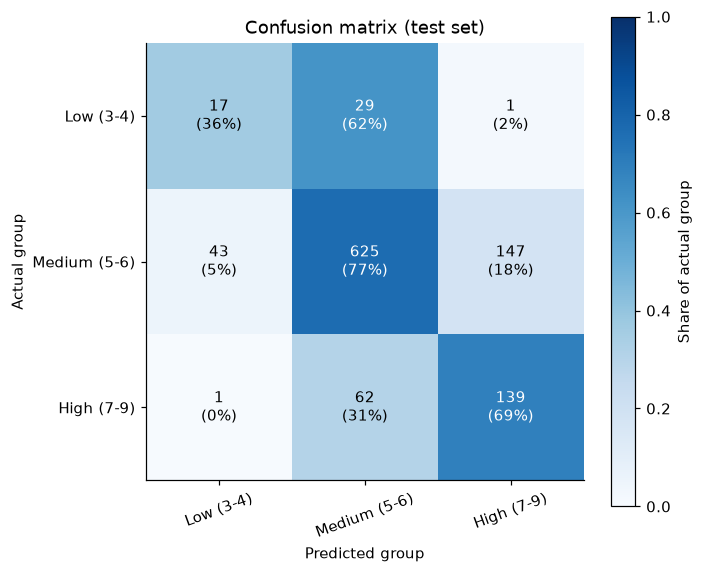

บันทึกกราฟ: fig04_confusion_matrix.png


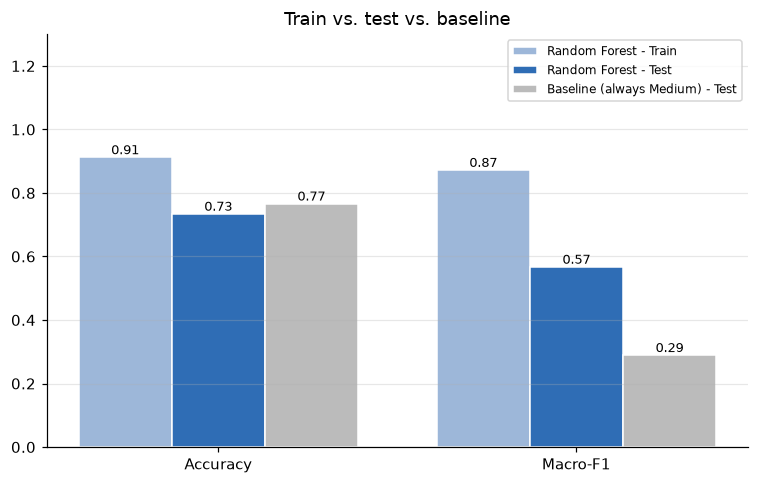

บันทึกกราฟ: fig05_train_test_baseline.png


In [6]:
# รายงานรายกลุ่มบนชุดทดสอบ (precision, recall, F1)
pred = best.predict(X_test)
rep = pd.DataFrame(classification_report(y_test, pred, target_names=GROUPS,
                                         output_dict=True, zero_division=0)).T.round(3)
rep.to_csv(TAB / "classification_report_test.csv")
print("บันทึกตาราง: classification_report_test.csv")
display(rep)

# กราฟที่ 4: confusion matrix (จำนวน และร้อยละของแต่ละแถว = recall)
cm = confusion_matrix(y_test, pred)
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(GROUPS, rotation=20)
ax.set_yticks(range(3)); ax.set_yticklabels(GROUPS)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]}\n({cmn[i, j] * 100:.0f}%)", ha="center", va="center",
                color="white" if cmn[i, j] > 0.5 else "black")
ax.grid(False)
ax.set_xlabel("Predicted group"); ax.set_ylabel("Actual group")
fig.colorbar(im, ax=ax, label="Share of actual group")
ax.set_title("Confusion matrix (test set)")
save("fig04_confusion_matrix.png")

# กราฟที่ 5: เปรียบเทียบความแม่นยำชุดฝึก / ชุดทดสอบ / baseline
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(2); w = 0.26
for k, (lab, col) in enumerate([("Random Forest - Train", "#9db7d9"),
                                ("Random Forest - Test", BLUE),
                                ("Baseline (always Medium) - Test", "#bbbbbb")]):
    vals = res.loc[res["dataset"] == lab, ["Accuracy", "Macro-F1"]].values[0]
    b = ax.bar(x + (k - 1) * w, vals, w, label=lab, color=col, edgecolor="white")
    for xi, v in zip(x + (k - 1) * w, vals):
        ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(["Accuracy", "Macro-F1"])
ax.set_ylim(0, 1.3); ax.set_title("Train vs. test vs. baseline")
ax.legend(loc="upper right", fontsize=8); ax.grid(axis="x", visible=False)
save("fig05_train_test_baseline.png")


**อ่านผลรายกลุ่ม (ชุดทดสอบ):**
- Medium: recall 0.77, precision 0.87 — ทำได้ดีที่สุด เพราะมีข้อมูลมากที่สุด
- High: recall 0.69 แต่ precision 0.48 — จับไวน์คุณภาพสูงได้ราวสองในสาม แต่ทายผิดเข้ามาพอสมควร (Medium ถูกทายเป็น High 147 ขวด)
- Low: recall 0.36, precision 0.28 — ทำได้อ่อนที่สุด เพราะในชุดทดสอบมีเพียง 47 ขวด

## 3. ตรวจความเสถียรและตัวแปรสำคัญ

ผล Stratified 5-fold (ตัดแถวซ้ำ)


,Fold,Train Acc,Test Acc,Gap (Diff),Test Macro-F1,Baseline Acc
0,1,0.9055,0.7227,0.1828,0.5604,0.766
1,2,0.9001,0.7340,0.1661,0.5460,0.766
2,3,0.9095,0.7528,0.1567,0.6181,0.766
3,4,0.9093,0.7519,0.1574,0.5726,0.766
4,5,0.9093,0.7359,0.1734,0.6105,0.766



Mean Test Accuracy: 0.7395 | Mean Test Macro-F1: 0.5815 | Mean Baseline: 0.7660


,feature,importance,sd
5,free sulfur dioxide,0.0741,0.0126
10,alcohol,0.0733,0.0152
1,volatile acidity,0.0244,0.0100
6,total sulfur dioxide,0.0184,0.0130
9,sulphates,0.0157,0.0099
3,residual sugar,0.0103,0.0087
7,density,0.0099,0.0102
4,chlorides,0.0056,0.0089
8,pH,0.0053,0.0080
11,type_encoded,0.0029,0.0056


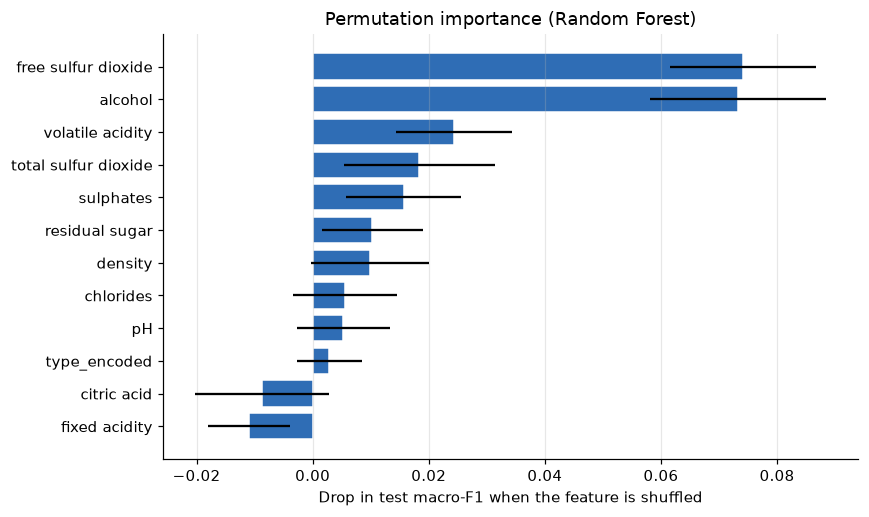

บันทึกกราฟ: fig06_feature_importance.png


In [7]:
# ตรวจความเสถียรด้วย Stratified 5-fold บนข้อมูลที่ตัดแถวซ้ำทั้งหมด (ฝึกใหม่ในแต่ละ fold)
from sklearn.base import clone
skf = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for k, (tr, te) in enumerate(skf.split(X, y), start=1):
    m = clone(best).fit(X.iloc[tr], y.iloc[tr])
    tr_acc = accuracy_score(y.iloc[tr], m.predict(X.iloc[tr]))
    te_acc = accuracy_score(y.iloc[te], m.predict(X.iloc[te]))
    rows.append({"Fold": k, "Train Acc": tr_acc, "Test Acc": te_acc, "Gap (Diff)": tr_acc - te_acc,
                 "Test Macro-F1": f1_score(y.iloc[te], m.predict(X.iloc[te]), average="macro"),
                 "Baseline Acc": (y.iloc[te] == 1).mean()})
cv = pd.DataFrame(rows).round(4)
cv.to_csv(TAB / "cv_by_fold.csv", index=False)
print("ผล Stratified 5-fold (ตัดแถวซ้ำ)")
display(cv)
print(f"\nMean Test Accuracy: {cv['Test Acc'].mean():.4f} | Mean Test Macro-F1: {cv['Test Macro-F1'].mean():.4f}"
      f" | Mean Baseline: {cv['Baseline Acc'].mean():.4f}")

# ความสำคัญของตัวแปร (permutation importance บนชุดทดสอบ)
from sklearn.inspection import permutation_importance
pi = permutation_importance(best, X_test, y_test, n_repeats=15, random_state=42,
                            scoring="f1_macro", n_jobs=-1)
imp = (pd.DataFrame({"feature": MODEL_FEATURES, "importance": pi.importances_mean,
                     "sd": pi.importances_std}).sort_values("importance", ascending=False).round(4))
imp.to_csv(TAB / "feature_importance.csv", index=False)
display(imp)

# กราฟที่ 6: ความสำคัญของตัวแปร
t = imp.sort_values("importance")
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(t["feature"], t["importance"], xerr=t["sd"], color=BLUE, edgecolor="white")
ax.set_xlabel("Drop in test macro-F1 when the feature is shuffled")
ax.set_title("Permutation importance (Random Forest)")
ax.grid(axis="y", visible=False)
save("fig06_feature_importance.png")


**อ่านผล:** Stratified 5-fold ให้ accuracy เฉลี่ย 0.74 และ macro-F1 เฉลี่ย 0.58 สอดคล้องกับชุดทดสอบ (0.73 / 0.57) ทุก fold มี gap ระหว่างชุดฝึกกับชุดทดสอบราว 0.16–0.18 ยืนยันว่า overfitting เกิดสม่ำเสมอ ไม่ใช่เพราะการแบ่งข้อมูลบังเอิญ ตัวแปรที่สำคัญที่สุดคือ `free sulfur dioxide` และ `alcohol` (ใกล้เคียงกัน) ตามด้วย `volatile acidity` ส่วนตัวแปรท้ายตาราง (`citric acid`, `fixed acidity`) ติดลบ แปลว่าไม่ช่วยพยากรณ์

In [8]:
# เวอร์ชันของโปรแกรมที่ใช้ (ใส่ใน README และ requirements.txt)
import sys, sklearn
print("Python", sys.version.split()[0])
print("pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", plt.matplotlib.__version__, "| scikit-learn", sklearn.__version__)


Python 3.14.7
pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2 | scikit-learn 1.9.1


## สรุปและข้อจำกัด

- โมเดลจัดกลุ่มคุณภาพได้ macro-F1 ≈ 0.57 ดีกว่า baseline (0.29) แต่ accuracy (0.73) ไม่ชนะการทายกลุ่ม Medium เสมอ (0.77) จึงเหมาะใช้คัดไวน์กลุ่ม High/Low มากกว่าการทายคะแนนทุกขวด
- มี overfitting ชัดเจน (ฝึก 0.91 / ทดสอบ 0.73) การจำกัดความลึกต้นไม้หรือเพิ่ม `min_samples_leaf` จะลด gap ได้ แต่ accuracy ชุดทดสอบเพิ่มไม่มาก
- กลุ่ม Low มีข้อมูลน้อย (4.4%) ผลของกลุ่มนี้จึงไม่นิ่ง
- คะแนน `quality` มาจากผู้ชิม มีความเป็นอัตวิสัย